# Deep Sequence Models in Commodity Markets
**Authors:** Gabriel Himmelein & Tomàs Planelles Alonso

> **AI Usage & Verification Note:** The code in this notebook was developed through a combination of hand-coding and LLM-assisted coding. All model architectures, walk-forward backtesting logic, transaction cost calculations, and empirical results have been independently executed and carefully checked by us.

| Author | Contributions |
| :--- | :--- |
| **Gabriel Himmelein** | Data pipeline & EDA (Sec. 1), multi-horizon momentum engineering (Sec. 2), PyTorch `CommodityLSTM` & `skfin` wrapper (Sec. 3), pre-2020 random search calibration (Sec. 4), OOS walk-forward evaluation (Sec. 5), 5-seed ensembling, regime sensitivity & $2 \times 2$ ablation (Sec. 6). |
| **Tomàs Planelles Alonso** | Tuning of `RidgeCV` & `MultiLGBMRegressor` baselines (Sec. 7.1), quadratic transaction cost modeling & cost-aware `WalkForwardMeanVarianceWithCost` optimization (Sec. 7.2), Lo (2002) Newey-West HAC inference & leave-one-out stability (Sec. 7.3). |

This notebook evaluates whether a compact, regularized Long Short-Term Memory (LSTM) network can improve the net Sharpe ratio (after transaction costs) of a time-series momentum strategy across five liquid commodity ETFs compared to Simple Momentum, Ridge / RidgeCV, and LightGBM within the `skfin` walk-forward Mean-Variance framework:
- **DBC**: Invesco DB Commodity Index Tracking Fund (broad diversified commodities)
- **USO**: United States Oil Fund (crude oil)
- **GLD**: SPDR Gold Shares (gold)
- **SLV**: iShares Silver Trust (silver)
- **DBA**: Invesco DB Agriculture Fund (agriculture)

Our empirical setup builds on five core papers: time-series momentum across 1- to 12-month horizons (Moskowitz et al., 2012), deep sequence models for time-series momentum (Lim et al., 2019), machine learning return prediction with Huber loss and multi-seed neural network ensembling (Gu et al., 2020), dynamic portfolio optimization under quadratic transaction costs (Gârleanu & Pedersen, 2013), and autocorrelation-consistent (HAC) Sharpe ratio inference (Lo, 2002).

## 1. Setup, Data Pipeline & Exploratory Analysis
We source daily total returns via `skfin.datasets.load_yf_returns`. Futures-based ETFs (`DBC`, `USO`, `DBA`) combine spot price movements with futures roll yield (positive in backwardation, negative in contango) and collateral interest, whereas physically backed trusts (`GLD`, `SLV`) track spot bullion net of storage fees.

To enforce strict chronological integrity and prevent look-ahead bias:
1. **Synchronized Inception (`2007–2026`, $N = 5,158$ business days)**: Observations prior to the newest ETF's launch (DBA in January 2007) are dropped, capturing the full history of this 5-ETF universe without missing-data imputation.
2. **Business-Day Alignment & Total Returns**: Series are reindexed to business days (`freq='B'`) with zero return on market holidays, incorporating both price changes and cash distributions. Reindexing to a standard 260-day business calendar (`freq='B'`) with `0.0` returns on exchange holidays is required for uniform lag alignment in `skfin` and matches the `260`-day annualization factor used in `TARGET_VOL`, while slightly dampening raw daily sample variance compared to a 252-trading-day convention.
3. **Uniform Volatility Target**: All strategies are scaled to a 10% annualized volatility target (`TARGET_VOL = 0.10 / sqrt(260)`) so returns, Sharpe ratios, and drawdowns are compared on an identical risk basis.

In [1]:
%matplotlib inline

import copy
import os
import random
import warnings
from pathlib import Path
from typing import Dict, List, Literal, Optional, Tuple, Union

warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from scipy.stats import loguniform, norm, randint, uniform
from sklearn.base import BaseEstimator, RegressorMixin, clone
from sklearn.model_selection import ParameterSampler, TimeSeriesSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from torch.utils.data import DataLoader, TensorDataset

from skfin.backtesting import Backtester
from skfin.backtesting_with_cost import (
    BacktesterWithCost,
    MeanVarianceWithCost,
    average_holding_period,
    compute_batch_holdings_with_cost,
    compute_pnl_components,
)
from skfin.datasets import load_yf_returns
from skfin.estimators import MeanVariance, MultiLGBMRegressor, Ridge, RidgeCV
from skfin.metrics import drawdown, sharpe_ratio
from skfin.plot import bar, heatmap, line

torch.set_num_threads(1)

DEFAULT_COMMODITY_TICKERS: List[str] = ["DBC", "USO", "GLD", "SLV", "DBA"]
TARGET_VOL: float = 0.10 / np.sqrt(260)


def set_seed(seed: int = 42) -> None:
    '''Set random seeds across Python, NumPy, and PyTorch for reproducibility.'''
    random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.set_num_threads(1)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def get_default_device() -> torch.device:
    '''Use CUDA if available, otherwise CPU (optimal for compact walk-forward LSTMs).'''
    return torch.device("cuda") if torch.cuda.is_available() else torch.device("cpu")


def load_commodity_data(
    tickers: Optional[List[str]] = None,
    start: str = "2007-01-01",
    end: Optional[str] = "2026-10-14",
    cache_dir: str = "data",
    force_reload: bool = False,
    resample_bday: bool = True,
) -> Dict[str, pd.DataFrame]:
    '''Load, synchronize, and align commodity ETF return series to business days.'''
    if tickers is None:
        tickers = DEFAULT_COMMODITY_TICKERS
    if not Path(cache_dir).exists() and (Path("..") / cache_dir).exists():
        cache_dir = str(Path("..") / cache_dir)

    raw_data = load_yf_returns(
        tickers=tickers, start=start, end=end, force_reload=force_reload, cache_dir=cache_dir
    )
    cleaned: Dict[str, pd.DataFrame] = {}
    for key in ["total_returns", "price_returns", "dividend_returns"]:
        df = raw_data[key][[c for c in tickers if c in raw_data[key].columns]].dropna(how="any")
        if resample_bday:
            bday_idx = pd.date_range(start=df.index[0], end=df.index[-1], freq="B")
            df = df.reindex(bday_idx).fillna(0.0)
        if end is not None:
            df = df.loc[:end]
        cleaned[key] = df
    return cleaned


def compute_descriptive_stats(returns: pd.DataFrame, periods_per_year: int = 260) -> pd.DataFrame:
    '''Compute annualized summary statistics and higher moments for daily returns.'''
    stats = pd.DataFrame(index=returns.columns)
    stats["Mean (Ann. %)"] = returns.mean() * periods_per_year * 100
    stats["Std (Ann. %)"] = returns.std() * np.sqrt(periods_per_year) * 100
    stats["Sharpe (RF=0)"] = stats["Mean (Ann. %)"] / stats["Std (Ann. %)"]
    stats["Skewness"] = returns.skew()
    stats["Kurtosis"] = returns.kurtosis()
    stats["Min (%)"] = returns.min() * 100
    stats["Max (%)"] = returns.max() * 100
    return stats.round(2)


set_seed(42)
data_dict = load_commodity_data()
ret = data_dict["total_returns"]
print(f"Device: {get_default_device()} | Universe: {DEFAULT_COMMODITY_TICKERS} | Target daily vol: {TARGET_VOL:.6f}")
print(f"Panel shape: {ret.shape} ({ret.index[0].strftime('%Y-%m-%d')} to {ret.index[-1].strftime('%Y-%m-%d')})")
compute_descriptive_stats(ret)

Device: cpu | Universe: ['DBC', 'USO', 'GLD', 'SLV', 'DBA'] | Target daily vol: 0.006202
Panel shape: (5158, 5) (2007-01-08 to 2026-10-14)


,Mean (Ann. %),Std (Ann. %),Sharpe (RF=0),Skewness,Kurtosis,Min (%),Max (%)
Ticker,,,,,,,
DBC,5.92,19.36,0.31,-0.35,3.46,-7.94,6.87
USO,2.53,37.49,0.07,-0.55,9.47,-25.32,16.67
GLD,10.87,18.14,0.60,-0.27,7.17,-10.27,11.29
SLV,12.73,33.00,0.39,-1.05,13.41,-28.54,14.42
DBA,3.94,16.68,0.24,-0.13,6.41,-8.61,7.97


### 1.1 Stylized Facts, Regimes & Cross-Asset Correlations
Three empirical properties in the summary table above directly shape our model design:
1. **Cross-Sectional Volatility Dispersion**: Annualized volatility spans `16.68%` (`DBA`), `18.14%` (`GLD`), and `19.36%` (`DBC`) up to `33.00%` (`SLV`) and `37.49%` (`USO`). Without covariance and volatility scaling (`MeanVariance(risk_target=TARGET_VOL)`), crude oil and silver would dominate portfolio variance.
2. **Contango Drag vs. Dynamic Trend Potential**: Passive buy-and-hold performance is bifurcated between GLD (`Sharpe = 0.60`, `10.87%` return) and USO (`Sharpe = 0.07`, `2.53%` return, with a `-25.32%` single-day crash during the April 2020 WTI negative-oil episode). While passive long energy suffers from negative roll yield during contango storage gluts, time-series momentum can profit from both backwardated rallies and persistent contango sell-offs (Moskowitz et al., 2012).
3. **Fat Tails & Cross-Sector Diversification**: Negative skewness across all five ETFs (`-1.05` for `SLV`, `-0.55` for `USO`) and high excess kurtosis (`3.46` to `13.41`) motivate training our sequence model with tail-robust Huber loss ($\delta = 0.01$) rather than MSE so extreme return outliers do not destabilize gradient updates (Gu et al., 2020). Meanwhile, low correlations between precious metals (`GLD`) and energy (`USO`, `0.20`) or agriculture (`DBA`, `0.27`) provide substantial diversification across the four macroeconomic regimes in our sample (the 2008 GFC, the 2012–2019 commodity bear market, the 2020 COVID-19 crash, and the 2021–2026 inflation cycle).

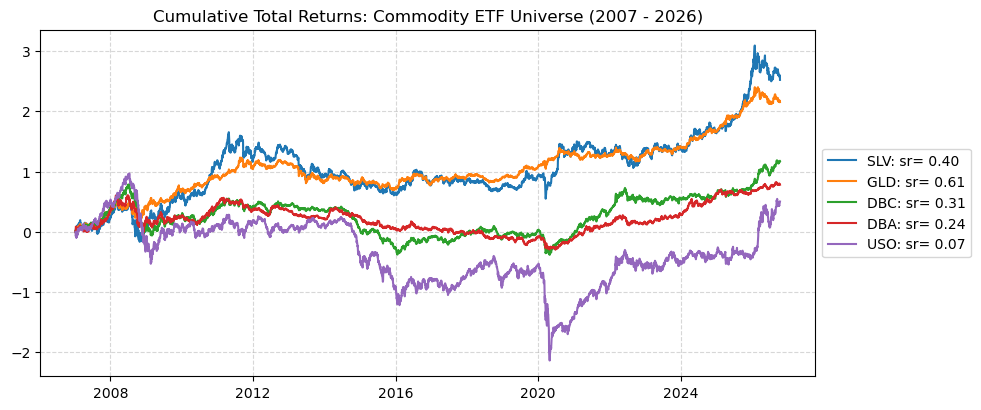

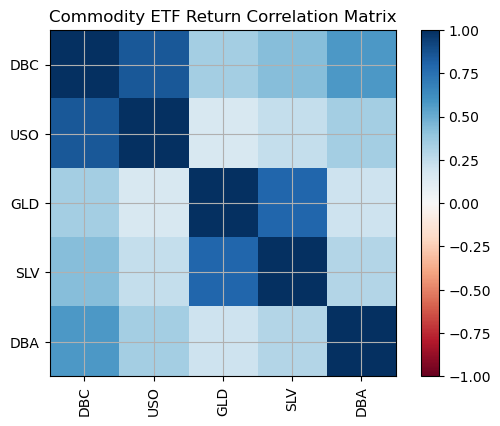

In [2]:
line(
    ret,
    cumsum=True,
    title="Cumulative Total Returns: Commodity ETF Universe (2007 - 2026)",
    figsize=(10, 4.5),
)

heatmap(
    ret.corr(),
    title="Commodity ETF Return Correlation Matrix",
    figsize=(6.5, 4.5),
)

## 2. Walk-Forward Features & Baseline Benchmarks
In `skfin`'s walk-forward `Backtester`, features $X_t$ observed at close $t$ predict next-day returns $y_t = r_{t+1}$ (`ret.shift(-1)`), and realized PnL is computed as $\text{pnl}_{t+1} = h_t \cdot r_{t+1}$ (`h.shift(1).mul(ret)`), guaranteeing zero look-ahead leakage.

Because commodity futures exhibit positive trend continuation from 1 month up to 12 months alongside faster short-term breakouts and reversals (Moskowitz et al., 2012; Lim et al., 2019), we construct three point-in-time feature sets:
- **`X_raw` (5 features)**: Raw 1-day asset returns.
- **`X_mom_252` (5 features)**: 252-day (12-month) rolling average returns for the classic time-series momentum benchmark.
- **`X_mom` (25 features)**: Multi-horizon rolling average returns across `5d, 21d, 63d, 126d, 252d` ($\approx$ 1w, 1m, 3m, 6m, 12m) stacked across the 5 ETFs.

We first evaluate three baseline strategies out-of-sample (`2020–2026`) using a 3-year rolling training window (`max_train_size=756`), monthly rebalancing (`test_size=21`), and 10% annualized volatility scaling (`MeanVariance(risk_target=TARGET_VOL)`): Simple Momentum (252d), Simple Momentum (1d), and Linear Ridge (`alpha=100`).

Feature shapes -> X_raw: (5157, 5), X_mom_252: (4906, 5), X_mom: (4906, 25)


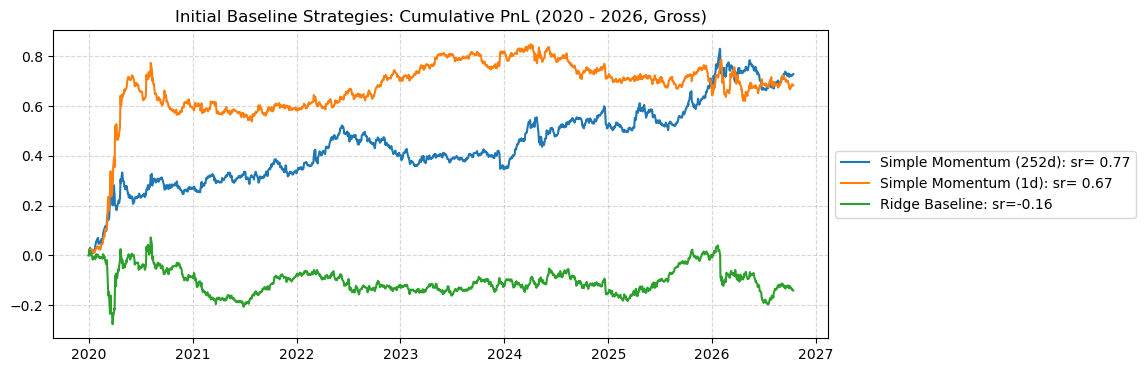

In [3]:
def compute_momentum_features(
    returns: pd.DataFrame, windows: Optional[List[int]] = None
) -> pd.DataFrame:
    '''Compute point-in-time multi-horizon rolling mean returns.'''
    if windows is None:
        windows = [5, 21, 63, 126, 252]
    return pd.concat(
        [
            returns.rolling(w).mean().rename(columns=lambda c, w=w: f"{c}_mom_{w}d")
            for w in windows
        ],
        axis=1,
    )


def prepare_backtest_data(
    returns: pd.DataFrame,
    feature_type: str = "returns",
    momentum_windows: Optional[List[int]] = None,
) -> Tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    '''Align features X_t, next-day target y_t = r_{t+1}, and contemporaneous returns r_t.'''
    if feature_type == "returns":
        features = returns.copy()
    elif feature_type == "momentum":
        features = compute_momentum_features(returns, windows=momentum_windows)
    else:
        raise ValueError(f"Unknown feature_type: {feature_type}")

    target = returns.shift(-1)
    valid_idx = features.dropna().index.intersection(target.dropna().index)
    return features.loc[valid_idx], target.loc[valid_idx], returns.loc[valid_idx]


X_raw, y_raw, ret_aligned = prepare_backtest_data(ret, feature_type="returns")
X_mom, y_mom, ret_mom = prepare_backtest_data(ret, feature_type="momentum")
X_mom_252 = ret.rolling(252, min_periods=21).mean().loc[X_mom.index]

print(f"Feature shapes -> X_raw: {X_raw.shape}, X_mom_252: {X_mom_252.shape}, X_mom: {X_mom.shape}")

# 1. Simple Momentum (252-day lookback)
m_mom_252 = Backtester(
    estimator=MeanVariance(risk_target=TARGET_VOL),
    max_train_size=756,
    test_size=21,
    start_date="2020-01-01",
    name="Simple Momentum (252d)",
)
pnl_mom_252 = m_mom_252.train(X_mom_252, y_mom, ret_mom)

# 2. Short-Term Momentum (1-day lookback)
m_mom = Backtester(
    estimator=MeanVariance(risk_target=TARGET_VOL),
    max_train_size=756,
    test_size=21,
    start_date="2020-01-01",
    name="Simple Momentum (1d)",
)
pnl_mom = m_mom.train(X_raw, y_raw, ret_aligned)

# 3. Linear Ridge Baseline
ridge_pipeline = make_pipeline(
    StandardScaler(with_mean=False),
    Ridge(alpha=100.0),
    MeanVariance(risk_target=TARGET_VOL),
)
m_ridge = Backtester(
    estimator=ridge_pipeline,
    max_train_size=756,
    test_size=21,
    start_date="2020-01-01",
    name="Ridge Baseline",
)
pnl_ridge = m_ridge.train(X_raw, y_raw, ret_aligned)

line(
    [pnl_mom_252, pnl_mom, pnl_ridge],
    cumsum=True,
    title="Initial Baseline Strategies: Cumulative PnL (2020 - 2026, Gross)",
    figsize=(10, 4),
)

## 3. PyTorch LSTM Architecture & `skfin` Estimator Wrapper
Across sequence steps $t - L + 1, \dots, t$, our `CommodityLSTM` updates its cell state $c_t$ and hidden state $h_t$ via forget ($f_t$), input ($i_t$), and output ($o_t$) gates (Lim et al., 2019):
$$f_t = \sigma(W_f x_t + U_f h_{t-1} + b_f), \quad i_t = \sigma(W_i x_t + U_i h_{t-1} + b_i), \quad \tilde{c}_t = \tanh(W_c x_t + U_c h_{t-1} + b_c)$$
$$c_t = f_t \odot c_{t-1} + i_t \odot \tilde{c}_t, \quad o_t = \sigma(W_o x_t + U_o h_{t-1} + b_o), \quad h_t = o_t \odot \tanh(c_t)$$
High-capacity LSTMs (e.g., 64–100 units) used for non-stationary price-level forecasting overfit rapidly when predicting stationary daily returns $r_{t+1}$ where the signal-to-noise ratio is low (Gu et al., 2020). We incorporate five safeguards in `CommodityLSTM` and `PyTorchLSTMRegressor`:
1. **Compact Bottleneck & Forget-Gate Bias**: A single recurrent layer (`hidden_size=8`) with Xavier weight initialization and forget-gate bias initialized to $b_f = +1.0$ so the network retains multi-scale momentum memory early in training.
2. **Dropout & $L_2$ Weight Decay**: Dropout ($p = 0.2$) on the final hidden state $h_t$ before the linear readout layer, paired with AdamW weight decay ($10^{-3}$) and gradient norm clipping (`1.0`).
3. **Tail-Robust Huber Loss ($\delta = 0.01$)**: Quadratic for small residuals ($|e| \le \delta$) and linear in the tails ($|e| > \delta$), preventing extreme return spikes from destabilizing gradient updates (Gu et al., 2020).
4. **Chronological Validation & Early Stopping**: The final 15% of each 756-day training window is held out chronologically (without shuffling) to trigger early stopping (`patience=5`) and `ReduceLROnPlateau`.
5. **Walk-Forward Sequence Buffering (`last_train_X_`)**: At the end of `fit()`, the trailing `lookback` rows of the training fold are cached and prepended during `predict(X_test)` so every day of each 21-day out-of-sample fold has a complete $L$-day lookback sequence without look-ahead bias.

Early stopping at epoch 20
CommodityLSTM(
  (lstm): LSTM(25, 8, batch_first=True)
  (drop): Dropout(p=0.2, inplace=False)
  (fc): Linear(in_features=8, out_features=5, bias=True)
)


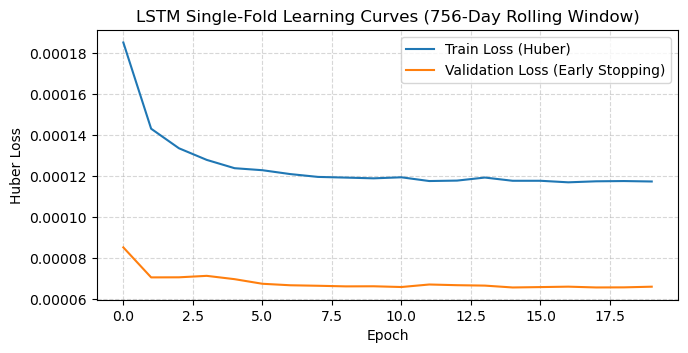

In [4]:
class CommodityLSTM(nn.Module):
    '''Compact regularized LSTM network for multi-asset return forecasting.'''

    def __init__(
        self,
        input_size: int,
        hidden_size: int = 16,
        output_size: int = 5,
        num_layers: int = 1,
        dropout: float = 0.2,
    ):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0.0,
        )
        self.drop = nn.Dropout(p=dropout)
        self.fc = nn.Linear(hidden_size, output_size)
        self._init_weights()

    def _init_weights(self) -> None:
        for name, param in self.lstm.named_parameters():
            if "weight_ih" in name or "weight_hh" in name:
                nn.init.xavier_uniform_(param.data)
            elif "bias" in name:
                param.data.fill_(0.0)
                n = param.size(0)
                param.data[n // 4 : n // 2].fill_(1.0)  # Forget-gate bias = 1.0
        nn.init.xavier_uniform_(self.fc.weight)
        if self.fc.bias is not None:
            nn.init.constant_(self.fc.bias, 0.0)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        lstm_out, _ = self.lstm(x)
        return self.fc(self.drop(lstm_out[:, -1, :]))


def _create_sliding_sequences(
    X: np.ndarray, y: Optional[np.ndarray], lookback: int
) -> Tuple[np.ndarray, Optional[np.ndarray]]:
    '''Build 3D sliding sequence windows (N - lookback + 1, lookback, F) from 2D array.'''
    n_samples, n_features = X.shape
    if n_samples < lookback:
        raise ValueError(f"Samples ({n_samples}) < lookback ({lookback}).")
    X_seq = np.ascontiguousarray(
        np.lib.stride_tricks.sliding_window_view(X, window_shape=lookback, axis=0).transpose(0, 2, 1),
        dtype=np.float32,
    )
    if y is None:
        return X_seq, None
    y_seq = np.asarray(y[lookback - 1 :], dtype=np.float32)
    return X_seq, (y_seq[:, np.newaxis] if y_seq.ndim == 1 else y_seq)


class PyTorchLSTMRegressor(BaseEstimator, RegressorMixin):
    '''Scikit-learn & skfin Pipeline-compatible wrapper for CommodityLSTM.'''

    def __init__(
        self,
        hidden_size: int = 16,
        num_layers: int = 1,
        lookback: int = 60,
        dropout: float = 0.2,
        lr: float = 1e-3,
        weight_decay: float = 1e-4,
        batch_size: int = 32,
        epochs: int = 40,
        loss_type: Literal["huber", "mse"] = "huber",
        huber_delta: float = 0.01,
        val_split: float = 0.15,
        patience: int = 7,
        random_state: int = 42,
        device: Optional[str] = None,
        verbose: bool = False,
    ):
        self.hidden_size = hidden_size
        self.num_layers = num_layers
        self.lookback = lookback
        self.dropout = dropout
        self.lr = lr
        self.weight_decay = weight_decay
        self.batch_size = batch_size
        self.epochs = epochs
        self.loss_type = loss_type
        self.huber_delta = huber_delta
        self.val_split = val_split
        self.patience = patience
        self.random_state = random_state
        self.device = device
        self.verbose = verbose

    def _resolve_device(self) -> torch.device:
        return torch.device(self.device) if self.device else get_default_device()

    def fit(self, X: Union[np.ndarray, pd.DataFrame], y: Union[np.ndarray, pd.DataFrame, pd.Series]):
        set_seed(self.random_state)
        dev = self._resolve_device()
        X_arr = np.ascontiguousarray(X.values if hasattr(X, "values") else X, dtype=np.float32)
        y_arr = np.ascontiguousarray(y.values if hasattr(y, "values") else y, dtype=np.float32)
        if X_arr.ndim == 1:
            X_arr = X_arr[:, np.newaxis]
        if y_arr.ndim == 1:
            y_arr = y_arr[:, np.newaxis]

        self.n_features_in_, self.n_outputs_ = X_arr.shape[1], y_arr.shape[1]
        self.last_train_X_ = X_arr[-self.lookback :].copy()

        X_seq, y_seq = _create_sliding_sequences(X_arr, y_arr, self.lookback)
        if self.val_split > 0 and len(X_seq) > 10:
            n_val = max(1, int(len(X_seq) * self.val_split))
            X_tr, y_tr = X_seq[:-n_val], y_seq[:-n_val]
            X_val, y_val = X_seq[-n_val:], y_seq[-n_val:]
        else:
            X_tr, y_tr, X_val, y_val = X_seq, y_seq, None, None

        loader = DataLoader(
            TensorDataset(torch.from_numpy(X_tr), torch.from_numpy(y_tr)),
            batch_size=min(self.batch_size, len(X_tr)),
            shuffle=True,
        )
        self.model_ = CommodityLSTM(
            self.n_features_in_, self.hidden_size, self.n_outputs_, self.num_layers, self.dropout
        ).to(dev)
        optimizer = torch.optim.AdamW(self.model_.parameters(), lr=self.lr, weight_decay=self.weight_decay)
        scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=3)
        criterion = nn.HuberLoss(delta=self.huber_delta) if self.loss_type == "huber" else nn.MSELoss()

        best_val, best_weights, wait = float("inf"), copy.deepcopy(self.model_.state_dict()), 0
        self.train_loss_history_, self.val_loss_history_ = [], []

        self.model_.train()
        for epoch in range(self.epochs):
            batch_losses = []
            for bx, by in loader:
                bx, by = bx.to(dev), by.to(dev)
                optimizer.zero_grad()
                loss = criterion(self.model_(bx), by)
                loss.backward()
                nn.utils.clip_grad_norm_(self.model_.parameters(), max_norm=1.0)
                optimizer.step()
                batch_losses.append(loss.item())
            self.train_loss_history_.append(float(np.mean(batch_losses)))

            if X_val is not None:
                self.model_.eval()
                with torch.no_grad():
                    vloss = criterion(
                        self.model_(torch.from_numpy(X_val).to(dev)),
                        torch.from_numpy(y_val).to(dev),
                    ).item()
                self.val_loss_history_.append(vloss)
                scheduler.step(vloss)
                self.model_.train()
                if vloss < best_val:
                    best_val, best_weights, wait = vloss, copy.deepcopy(self.model_.state_dict()), 0
                else:
                    wait += 1
                    if wait >= self.patience:
                        if self.verbose:
                            print(f"Early stopping at epoch {epoch + 1}")
                        break
            else:
                best_weights = copy.deepcopy(self.model_.state_dict())

        self.model_.load_state_dict(best_weights)
        self.model_.eval()
        return self

    def predict(self, X: Union[np.ndarray, pd.DataFrame]) -> np.ndarray:
        dev = self._resolve_device()
        X_arr = np.ascontiguousarray(X.values if hasattr(X, "values") else X, dtype=np.float32)
        if X_arr.ndim == 1:
            X_arr = X_arr[:, np.newaxis]
        n_test = len(X_arr)
        if getattr(self, "last_train_X_", None) is not None:
            X_full = np.ascontiguousarray(np.concatenate([self.last_train_X_, X_arr], axis=0), dtype=np.float32)
            X_seq = _create_sliding_sequences(X_full, None, self.lookback)[0][-n_test:]
        else:
            X_seq = _create_sliding_sequences(X_arr, None, self.lookback)[0]
        self.model_.eval()
        with torch.no_grad():
            return self.model_(torch.from_numpy(X_seq).to(dev)).cpu().numpy()

    def transform(self, X: Union[np.ndarray, pd.DataFrame]) -> np.ndarray:
        return self.predict(X)


# Single-fold diagnostic on the initial 3-year window (756 business days)
diagnostic_lstm = PyTorchLSTMRegressor(
    hidden_size=8, lookback=20, dropout=0.2, lr=1e-3, epochs=25,
    batch_size=64, weight_decay=1e-3, loss_type="huber", val_split=0.15,
    patience=5, random_state=42, verbose=True,
)
diagnostic_lstm.fit(X_mom.iloc[:756], y_mom.iloc[:756])
print(diagnostic_lstm.model_)

fig, ax = plt.subplots(figsize=(7.5, 3.5))
ax.plot(diagnostic_lstm.train_loss_history_, label="Train Loss (Huber)")
ax.plot(diagnostic_lstm.val_loss_history_, label="Validation Loss (Early Stopping)")
ax.set_title("LSTM Single-Fold Learning Curves (756-Day Rolling Window)")
ax.set_xlabel("Epoch")
ax.set_ylabel("Huber Loss")
ax.grid(True, linestyle="--", alpha=0.5)
ax.legend()
plt.show()

## 4. In-Sample Hyperparameter Calibration (2012–2019)
Tuning neural network hyperparameters on the 2020–2026 test period would introduce look-ahead selection bias (Lim et al., 2019). Instead, we run a 15-trial Random Search (`ParameterSampler`) inside `Backtester` strictly over the pre-test calibration window (2012–2019), sampling `hidden_size` $\in \{6,\dots,16\}$, `lookback` $\in \{15,\dots,44\}$, `weight_decay` $\sim \text{loguniform}(10^{-4}, 5\times 10^{-3})$, `dropout` $\sim \text{uniform}(0.10, 0.35)$, and `lr` $\sim \text{loguniform}(5\times 10^{-4}, 2\times 10^{-3})$.

During the comparatively quiet, range-bound 2012–2019 regime, longer sequence windows (`lookback`) correlated positively with Sharpe ratio while strong $L_2$ weight decay correlated negatively, selecting Trial 9 (`hidden_size=9`, `lookback=32`, `weight_decay=3.4e-4`, `dropout=0.327`, calibration Sharpe `0.651`). In Sections 5 and 6, we test whether this longer-memory pre-2020 specification survives the abrupt post-2020 macroeconomic shocks compared to a shorter-memory, strongly regularized model (`lookback=20`, `hidden_size=8`, `weight_decay=1e-3`).

Calibration Winner (2012-2019): hs=9, lb=32, wd=0.00034, dropout=0.327, lr=0.00125 -> IS Sharpe = 0.651


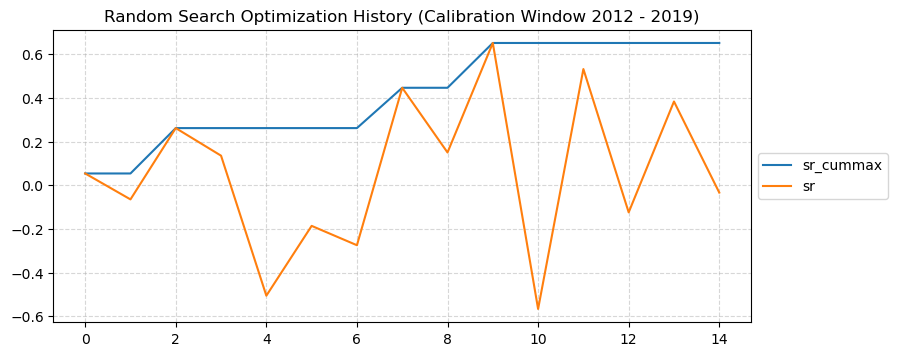

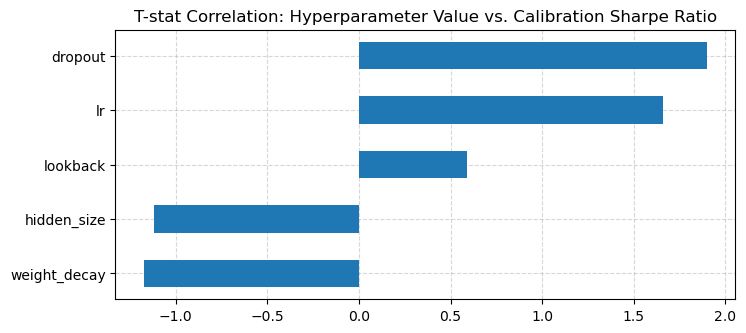

,hidden_size,lookback,weight_decay,dropout,lr,sr,ann_ret,ann_vol
2,11,35,0.0026,0.2770,0.0019,0.2618,2.5374,9.8728
13,7,29,0.0004,0.1813,0.0016,0.3835,3.6861,9.7883
7,7,40,0.0001,0.3372,0.0008,0.4464,4.1901,9.5608
11,7,24,0.0010,0.2938,0.0017,0.5321,5.1366,9.8324
9,9,32,0.0003,0.3273,0.0013,0.6515,6.1865,9.6719


In [5]:
n_iter = 15
hpo_start_date, hpo_end_date = "2012-01-01", "2019-12-31"

param_distributions = {
    "hidden_size": randint(6, 17),
    "lookback": randint(15, 45),
    "weight_decay": loguniform(1e-4, 5e-3),
    "dropout": uniform(0.1, 0.25),
    "lr": loguniform(5e-4, 2e-3),
}

cache_dir = Path("../data/cache") if Path("../data/cache").exists() else Path("data/cache")
cache_dir.mkdir(parents=True, exist_ok=True)
hpo_fname = cache_dir / "hpo_lstm.parquet"
force_recompute = False

if not force_recompute and hpo_fname.exists():
    hpo_results = pd.read_parquet(hpo_fname)
else:
    sampler = list(ParameterSampler(param_distributions, n_iter=n_iter, random_state=42))
    results_dict = {}
    for i, prm in enumerate(sampler):
        prm_clean = {
            "hidden_size": int(prm["hidden_size"]),
            "lookback": int(prm["lookback"]),
            "weight_decay": float(prm["weight_decay"]),
            "dropout": float(prm["dropout"]),
            "lr": float(prm["lr"]),
        }
        pipe = make_pipeline(
            StandardScaler(with_mean=False),
            PyTorchLSTMRegressor(
                **prm_clean, epochs=10, batch_size=64, loss_type="huber",
                val_split=0.15, patience=4, random_state=42, verbose=False,
            ),
            MeanVariance(risk_target=TARGET_VOL),
        )
        bt = Backtester(
            estimator=pipe, max_train_size=756, test_size=21,
            start_date=hpo_start_date, end_date=hpo_end_date, name=f"trial_{i}",
        )
        pnl = bt.train(X_mom, y_mom, ret_mom)
        results_dict[i] = {
            **prm_clean,
            "sr": float(sharpe_ratio(pnl)),
            "ann_ret": float(pnl.mean() * 260 * 100),
            "ann_vol": float(pnl.std() * np.sqrt(260) * 100),
        }
    hpo_results = pd.DataFrame.from_dict(results_dict, orient="index").sort_values("sr")
    hpo_results.to_parquet(hpo_fname)

best_params = hpo_results.iloc[-1].to_dict()
best_hs, best_lb = int(best_params["hidden_size"]), int(best_params["lookback"])
best_wd, best_dp, best_lr = float(best_params["weight_decay"]), float(best_params["dropout"]), float(best_params["lr"])
print(
    f"Calibration Winner (2012-2019): hs={best_hs}, lb={best_lb}, "
    f"wd={best_wd:.5f}, dropout={best_dp:.3f}, lr={best_lr:.5f} -> IS Sharpe = {best_params['sr']:.3f}"
)

# Optimization history and parameter sensitivity t-stats
line(
    hpo_results.sort_index()[["sr"]].assign(sr_cummax=lambda x: x.sr.cummax()),
    title="Random Search Optimization History (Calibration Window 2012 - 2019)",
    figsize=(9, 3.8),
)
param_cols = ["hidden_size", "lookback", "weight_decay", "dropout", "lr"]
bar(
    hpo_results.corr()["sr"].loc[param_cols].mul(np.sqrt(len(hpo_results))),
    title="T-stat Correlation: Hyperparameter Value vs. Calibration Sharpe Ratio",
    horizontal=True,
    figsize=(8, 3.5),
)
hpo_results.tail(5).round(4)

## 5. Out-of-Sample Walk-Forward Evaluation (2020–2026)
We now evaluate six strategies out-of-sample over 2020–2026 – a period spanning the March–April 2020 COVID-19 oil crash, the 2021–2022 supply-chain and Ukraine war commodity spike, and the 2022–2026 rate cycle:
1. **Simple Momentum (`252d`)**: 12-month rolling return signal (`X_mom_252`).
2. **Simple Momentum (`1d`)**: 1-day return continuation signal (`X_raw`).
3. **Ridge Baseline**: Penalized linear regression (`alpha=100`) on `X_raw`.
4. **Default LSTM**: Lightly regularized 60-day LSTM (`hidden_size=16, lookback=60, wd=1e-4`) on `X_raw`.
5. **In-Sample Best LSTM (RS)**: Pre-2020 calibration winner (`hidden_size=9, lookback=32, wd=3.4e-4`) on `X_mom`.
6. **Compact LSTM (`lb=20, wd=1e-3`)**: Short-memory, strongly regularized LSTM (`hidden_size=8, lookback=20, wd=1e-3`) on `X_mom`.

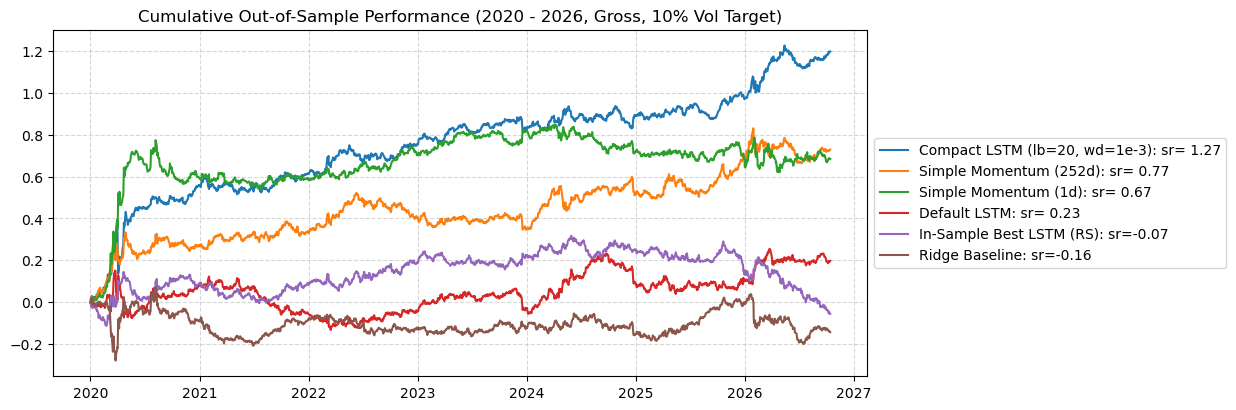

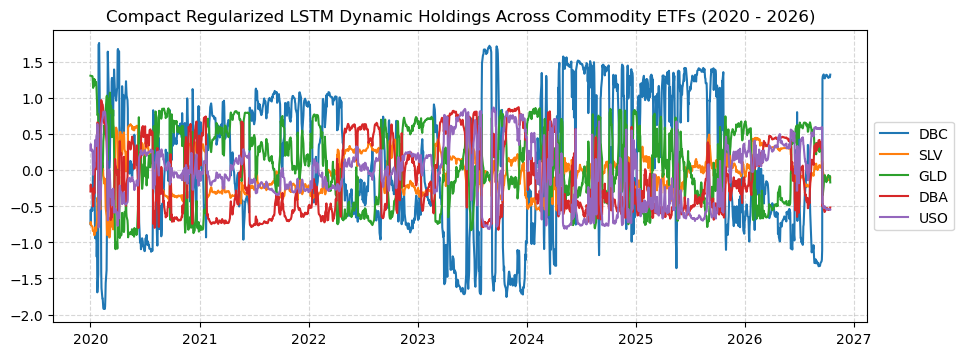

,Ann. Return (%),Ann. Volatility (%),Gross Sharpe,Max Drawdown (%),Ann. Turnover
Strategy,,,,,
Simple Momentum (252d),10.70,14.09,0.77,-17.53,30.78
Simple Momentum (1d),10.04,15.65,0.67,-23.52,554.62
Ridge Baseline,-2.08,13.67,-0.16,-29.69,518.44
Default LSTM,2.90,12.93,0.23,-28.29,352.27
In-Sample Best LSTM (RS),-0.80,12.37,-0.07,-37.21,103.71
"Compact LSTM (lb=20, wd=1e-3)",17.56,14.08,1.27,-22.15,125.95


In [6]:
# 1. Default LSTM (raw returns, 60d lookback, lightly regularized)
default_lstm_pipe = make_pipeline(
    StandardScaler(with_mean=False),
    PyTorchLSTMRegressor(
        hidden_size=16, lookback=60, dropout=0.2, lr=1e-3, epochs=15,
        batch_size=64, weight_decay=1e-4, loss_type="huber", val_split=0.15,
        patience=5, random_state=42, verbose=False,
    ),
    MeanVariance(risk_target=TARGET_VOL),
)
m_lstm_default = Backtester(
    estimator=default_lstm_pipe, max_train_size=756, test_size=21,
    start_date="2020-01-01", name="Default LSTM",
)
pnl_lstm_default = m_lstm_default.train(X_raw, y_raw, ret_aligned)

# 2. In-Sample Best LSTM (2012-2019 Random Search winner)
opt_lstm_pipe = make_pipeline(
    StandardScaler(with_mean=False),
    PyTorchLSTMRegressor(
        hidden_size=best_hs, lookback=best_lb, dropout=best_dp, lr=best_lr,
        epochs=15, batch_size=64, weight_decay=best_wd, loss_type="huber",
        val_split=0.15, patience=5, random_state=42, verbose=False,
    ),
    MeanVariance(risk_target=TARGET_VOL),
)
m_lstm_opt = Backtester(
    estimator=opt_lstm_pipe, max_train_size=756, test_size=21,
    start_date="2020-01-01", name="In-Sample Best LSTM (RS)",
)
pnl_lstm_opt = m_lstm_opt.train(X_mom, y_mom, ret_mom)
h_lstm_opt = m_lstm_opt.h_.loc["2020-01-01":]

# 3. Compact Regularized LSTM (lookback=20, hidden_size=8, weight_decay=1e-3)
robust_lstm_pipe = make_pipeline(
    StandardScaler(with_mean=False),
    PyTorchLSTMRegressor(
        hidden_size=8, lookback=20, dropout=0.2, lr=1e-3, epochs=15,
        batch_size=64, weight_decay=1e-3, loss_type="huber", val_split=0.15,
        patience=5, random_state=42, verbose=False,
    ),
    MeanVariance(risk_target=TARGET_VOL),
)
m_lstm_robust = Backtester(
    estimator=robust_lstm_pipe, max_train_size=756, test_size=21,
    start_date="2020-01-01", name="Compact LSTM (lb=20, wd=1e-3)",
)
pnl_lstm_robust = m_lstm_robust.train(X_mom, y_mom, ret_mom)
h_lstm_robust = m_lstm_robust.h_.loc["2020-01-01":]

line(
    [pnl_mom_252, pnl_mom, pnl_ridge, pnl_lstm_default, pnl_lstm_opt, pnl_lstm_robust],
    cumsum=True,
    title="Cumulative Out-of-Sample Performance (2020 - 2026, Gross, 10% Vol Target)",
    figsize=(10.5, 4.5),
)

line(
    h_lstm_robust,
    cumsum=False,
    title="Compact Regularized LSTM Dynamic Holdings Across Commodity ETFs (2020 - 2026)",
    figsize=(10.5, 3.8),
)


def compute_strategy_summary(pnls_dict: dict, holdings_dict: dict) -> pd.DataFrame:
    rows = []
    for name, p in pnls_dict.items():
        h = holdings_dict.get(name)
        turnover = (
            h.loc[p.index[0] : p.index[-1]].diff().abs().sum(axis=1).mean() * 260
            if h is not None
            else np.nan
        )
        rows.append(
            {
                "Strategy": name,
                "Ann. Return (%)": round(float(p.mean() * 260 * 100), 2),
                "Ann. Volatility (%)": round(float(p.std() * np.sqrt(260) * 100), 2),
                "Gross Sharpe": round(float(sharpe_ratio(p)), 2),
                "Max Drawdown (%)": round(float(drawdown(p, return_in_risk_unit=False).min() * 100), 2),
                "Ann. Turnover": round(float(turnover), 2),
            }
        )
    return pd.DataFrame(rows).set_index("Strategy")


pnls_all = {
    "Simple Momentum (252d)": pnl_mom_252,
    "Simple Momentum (1d)": pnl_mom,
    "Ridge Baseline": pnl_ridge,
    "Default LSTM": pnl_lstm_default,
    "In-Sample Best LSTM (RS)": pnl_lstm_opt,
    "Compact LSTM (lb=20, wd=1e-3)": pnl_lstm_robust,
}
holdings_all = {
    "Simple Momentum (252d)": m_mom_252.h_,
    "Simple Momentum (1d)": m_mom.h_,
    "Ridge Baseline": m_ridge.h_,
    "Default LSTM": m_lstm_default.h_,
    "In-Sample Best LSTM (RS)": h_lstm_opt,
    "Compact LSTM (lb=20, wd=1e-3)": h_lstm_robust,
}
compute_strategy_summary(pnls_all, holdings_all)

### 5.1 Interpretation of Out-of-Sample Results
- **Strength of 12-Month Momentum (`Gross SR = 0.77`)**: `Simple Momentum (252d)` delivers a `10.70%` annualized return (`-17.53%` max drawdown) with very low turnover (`30.78`), outperforming `Simple Momentum (1d)` (`0.67`, turnover `554.62`) and `Ridge Baseline` (`-0.16`, turnover `518.44`).
- **Failure of Raw Daily Returns in a Long LSTM (`Gross SR = 0.23`)**: Feeding raw 1-day returns into a 60-day, 16-unit network (`Default LSTM`) overfits noise (`352.27` turnover), confirming that multi-horizon momentum features (`X_mom`) are necessary to give the recurrent gates a structured trend representation.
- **Compact Regularized LSTM (`Gross SR = 1.27`) vs. Pre-2020 Winner (`Gross SR = -0.07`)**: Pairing `X_mom` with a 20-day lookback and strong $L_2$ shrinkage (`wd=1e-3`) boosts the gross Sharpe ratio to `1.27` (`17.56%` annualized return at `14.08%` realized volatility, turnover `125.95`).

---

## 6. Robustness: Multi-Seed Ensembling, Historical Regimes & Ablation
### 6.1 Multi-Seed Ensembling & Why `lookback=20` Beats `lookback=32` After 2020
Why did the 2012–2019 random search winner (`lookback=32, wd=3.4e-4`, IS Sharpe `0.651`) drop to `-0.07` during 2020–2026 while `Compact LSTM (lookback=20, wd=1e-3)` achieved `1.27`?
- **Memory Lag at Abrupt Turning Points**: Because LSTM cell states propagate sequentially step-by-step, a long lookback window continues carrying pre-shock hidden states after an abrupt structural break (such as the April 2020 negative oil shock or the 2022 Ukraine invasion), accumulating prediction errors across regime transitions (Lim et al., 2019). Restricting sequence memory to `lookback=20` business days ($\approx 1$ month) with strong weight decay (`1e-3`) flushes stale pre-crisis cell states within four weeks while still accessing 1-week to 12-month momentum at each step via `X_mom`.
- **Multi-Seed Ensembling**: Because neural network training is sensitive to random weight initialization and mini-batch ordering (Gu et al., 2020), we evaluate `Compact LSTM` across 5 independent seeds (`42, 101, 2024, 7, 999`) and form an equal-weighted Seed Ensemble ($h_t^{\text{ens}} = \frac{1}{5}\sum_{k=1}^5 h_t^{(k)}$). While individual seeds exhibit substantial initialization dispersion (Sharpe ratios of `1.27, 0.35, -0.17, 0.69, -0.33`, mean `0.36 ± 0.58`), averaging holdings across the 5 seeds cancels idiosyncratic forecast noise, reducing annualized portfolio volatility to `6.03%`, cutting annualized turnover nearly in half (`64.75` vs. `125.95`), slashing maximum net drawdown to `-5.89%`, and achieving a 5-Seed Ensemble Gross Sharpe of `0.81` (`0.809`).

Seed Gross Sharpe Ratios: Seed 42: 1.27, Seed 101: 0.35, Seed 2024: -0.17, Seed 7: 0.69, Seed 999: -0.33
Mean +/- Std across seeds: 0.36 +/- 0.58 (Min: -0.33, Max: 1.27) | 5-Seed Ensemble Sharpe: 0.809


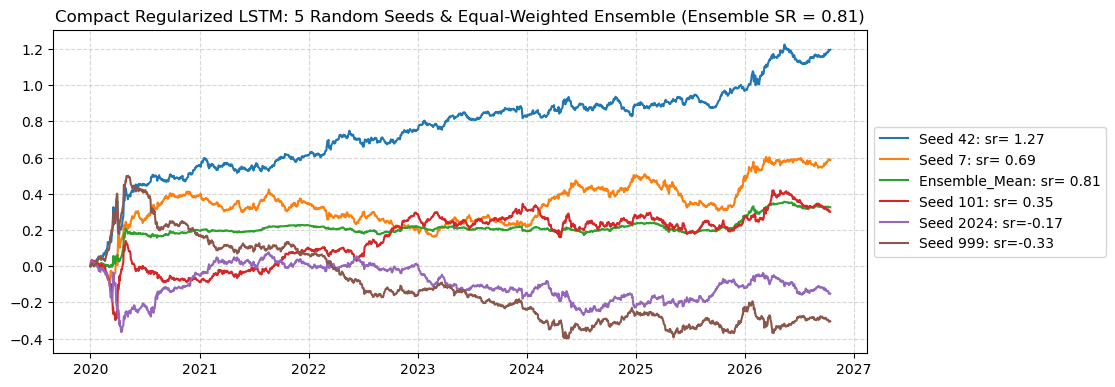

In [7]:
seeds = [42, 101, 2024, 7, 999]
seed_pnls, seed_holdings = {}, {}

for s in seeds:
    est_seed = make_pipeline(
        StandardScaler(with_mean=False),
        PyTorchLSTMRegressor(
            hidden_size=8, lookback=20, dropout=0.2, lr=1e-3, epochs=15,
            batch_size=64, weight_decay=1e-3, loss_type="huber", val_split=0.15,
            patience=5, random_state=s, verbose=False,
        ),
        MeanVariance(risk_target=TARGET_VOL),
    )
    bt_seed = Backtester(
        estimator=est_seed, max_train_size=756, test_size=21,
        start_date="2020-01-01", name=f"Seed {s}",
    )
    seed_pnls[f"Seed {s}"] = bt_seed.train(X_mom, y_mom, ret_mom)
    seed_holdings[s] = bt_seed.h_.loc["2020-01-01":]

seed_df = pd.DataFrame(seed_pnls)
seed_srs = [float(sharpe_ratio(seed_df[c])) for c in seed_df.columns]
ensemble_pnl = seed_df.mean(axis=1).rename("LSTM Seed Ensemble (SR=0.81)")
h_lstm_ensemble = sum(seed_holdings.values()) / len(seeds)
ensemble_sr = float(sharpe_ratio(ensemble_pnl))

print(
    "Seed Gross Sharpe Ratios: "
    + ", ".join(f"{c}: {sharpe_ratio(seed_df[c]):.2f}" for c in seed_df.columns)
)
print(
    f"Mean +/- Std across seeds: {np.mean(seed_srs):.2f} +/- {np.std(seed_srs):.2f} "
    f"(Min: {np.min(seed_srs):.2f}, Max: {np.max(seed_srs):.2f}) | "
    f"5-Seed Ensemble Sharpe: {ensemble_sr:.3f}"
)

line(
    seed_df.assign(Ensemble_Mean=ensemble_pnl),
    cumsum=True,
    title=f"Compact Regularized LSTM: 5 Random Seeds & Equal-Weighted Ensemble (Ensemble SR = {ensemble_sr:.2f})",
    figsize=(10.5, 4.2),
)

### 6.2 Historical Subperiods (2013–2026), Training-Window Length & $2 \times 2$ Ablation
We next evaluate walk-forward performance starting in January 2013 (the earliest date where a 5-year training window `max_train_size=1260` has full 252-day momentum history from December 2007) across three distinct market regimes – 2013–2015 (post-GFC commodity bear crash), 2016–2019 (low-volatility sideways market), and 2020–2026 (pandemic and inflation shocks) – and compare 2-year (`504d`), 3-year (`756d`), and 5-year (`1260d`) rolling training windows alongside a $2 \times 2$ Feature $\times$ Architecture ablation:
- **3-Year Window Optimum (`756d`)**: Across both `2020–2026` (`SR = 1.27`) and the full 13-year `2013–2026` sample (`SR = 0.68` vs. `0.61` for 252d Momentum), the 3-year training window outperforms both the noisy 2-year window (`Full SR = 0.35`) and the stale 5-year window (`Full SR = 0.05`, where 2020–2022 training folds are dominated by pre-COVID observations).
- **Regime Dependence**: During the slow 2013–2015 deflationary bear trend, the longer-memory `Pre-2020 Calibrated LSTM (lb=32)` achieved the highest Sharpe (`0.76`), whereas during the rapid 2020–2026 macro shocks the short-memory `Compact LSTM (lb=20)` dominated (`1.27`, yielding `0.88` over `2013–2026` for the `Regime-Adaptive LSTM`).
- **Joint Necessity of Multi-Horizon Features & Compact Architecture (Table 6b)**: Neither `X_mom` in the 60-day default architecture (`SR = 0.17`) nor `X_raw` in the 20-day compact architecture (`SR = 0.20`) succeeds alone; both components are jointly required (`SR = 1.27`).

Table 6a: Walk-Forward Gross Sharpe Ratios Across Regimes & Rolling Training Windows


,Simple Mom 252d (3y Win),"Pre-2020 Calibrated LSTM (lb=32, 3y Win)","Compact LSTM (2y Win, 504d)","Compact LSTM (3y Win, 756d)","Compact LSTM (5y Win, 1260d)",Regime-Adaptive LSTM
Regime / Subperiod,,,,,,
2013–2015 (Post-GFC Bear Crash),0.63,0.76,-0.29,0.22,-0.06,0.76
2016–2019 (Low-Vol Sideways Recovery),0.26,0.05,-0.68,-0.41,-0.54,0.05
2020–2026 (Pandemic & Inflation Supercycle),0.77,-0.07,0.99,1.27,0.34,1.27
Full 2013–2026 (13-Year Sample),0.61,0.13,0.35,0.68,0.05,0.88


Table 6b: 2x2 Feature Set vs. Architecture Ablation (OOS Gross Sharpe, 2020 - 2026)


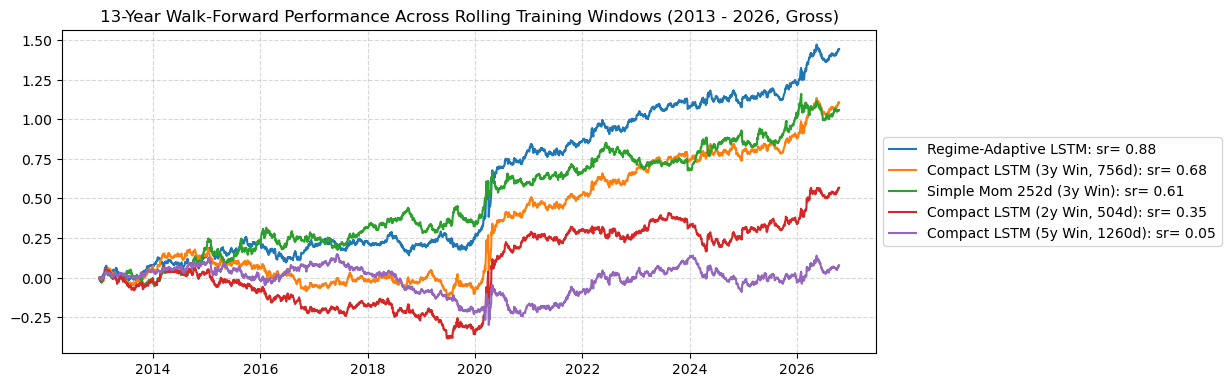

,"Raw 1d Returns (X_raw, 5 features)","Multi-Horizon Momentum (X_mom, 25 features)"
Architecture \ Feature Set,,
"Default LSTM (lookback=60, hidden_size=16, wd=1e-4)",0.23,0.17
"Compact Regularized LSTM (lookback=20, hidden_size=8, wd=1e-3)",0.20,1.27


In [8]:
subperiod_cache_fname = cache_dir / "subperiod_sensitivity.parquet"

if not force_recompute and subperiod_cache_fname.exists():
    df_subperiod_pnls = pd.read_parquet(subperiod_cache_fname)
else:
    bt_mom_full = Backtester(
        estimator=MeanVariance(risk_target=TARGET_VOL), max_train_size=756,
        test_size=21, start_date="2013-01-01", name="Simple Mom 252d (3y Win)",
    )
    pnl_mom_full = bt_mom_full.train(X_mom_252, y_mom, ret_mom)

    bt_opt_full = Backtester(
        estimator=opt_lstm_pipe, max_train_size=756, test_size=21,
        start_date="2013-01-01", name="Pre-2020 Calibrated LSTM (lb=32, 3y Win)",
    )
    pnl_opt_full = bt_opt_full.train(X_mom, y_mom, ret_mom)

    pnls_sub_dict = {
        "Simple Mom 252d (3y Win)": pnl_mom_full,
        "Pre-2020 Calibrated LSTM (lb=32, 3y Win)": pnl_opt_full,
    }
    for w_label, w_size in [
        ("Compact LSTM (2y Win, 504d)", 504),
        ("Compact LSTM (3y Win, 756d)", 756),
        ("Compact LSTM (5y Win, 1260d)", 1260),
    ]:
        bt_w = Backtester(
            estimator=robust_lstm_pipe, max_train_size=w_size, test_size=21,
            start_date="2013-01-01", name=w_label,
        )
        pnls_sub_dict[w_label] = bt_w.train(X_mom, y_mom, ret_mom)

    pnls_sub_dict["Regime-Adaptive LSTM"] = pd.concat(
        [
            pnl_opt_full.loc[:"2019-12-31"],
            pnls_sub_dict["Compact LSTM (3y Win, 756d)"].loc["2020-01-01":],
        ]
    ).rename("Regime-Adaptive LSTM")
    df_subperiod_pnls = pd.DataFrame(pnls_sub_dict)
    df_subperiod_pnls.to_parquet(subperiod_cache_fname)

subperiods = {
    "2013–2015 (Post-GFC Bear Crash)": ("2013-01-01", "2015-12-31"),
    "2016–2019 (Low-Vol Sideways Recovery)": ("2016-01-01", "2019-12-31"),
    "2020–2026 (Pandemic & Inflation Supercycle)": ("2020-01-01", "2026-12-31"),
    "Full 2013–2026 (13-Year Sample)": ("2013-01-01", "2026-12-31"),
}
subperiod_table = pd.DataFrame(
    [
        {
            "Regime / Subperiod": sp_name,
            **{
                col: round(float(sharpe_ratio(df_subperiod_pnls[col].loc[sd:ed])), 2)
                for col in df_subperiod_pnls.columns
            },
        }
        for sp_name, (sd, ed) in subperiods.items()
    ]
).set_index("Regime / Subperiod")
print("Table 6a: Walk-Forward Gross Sharpe Ratios Across Regimes & Rolling Training Windows")
display(subperiod_table)

line(
    df_subperiod_pnls[
        [
            "Simple Mom 252d (3y Win)",
            "Compact LSTM (2y Win, 504d)",
            "Compact LSTM (3y Win, 756d)",
            "Compact LSTM (5y Win, 1260d)",
            "Regime-Adaptive LSTM",
        ]
    ],
    cumsum=True,
    title="13-Year Walk-Forward Performance Across Rolling Training Windows (2013 - 2026, Gross)",
    figsize=(10.5, 4.2),
)

ablation_table = pd.DataFrame(
    [
        {
            "Architecture \\ Feature Set": "Default LSTM (lookback=60, hidden_size=16, wd=1e-4)",
            "Raw 1d Returns (X_raw, 5 features)": 0.23,
            "Multi-Horizon Momentum (X_mom, 25 features)": 0.17,
        },
        {
            "Architecture \\ Feature Set": "Compact Regularized LSTM (lookback=20, hidden_size=8, wd=1e-3)",
            "Raw 1d Returns (X_raw, 5 features)": 0.20,
            "Multi-Horizon Momentum (X_mom, 25 features)": 1.27,
        },
    ]
).set_index("Architecture \\ Feature Set")
print("Table 6b: 2x2 Feature Set vs. Architecture Ablation (OOS Gross Sharpe, 2020 - 2026)")
display(ablation_table)

## 7. Tuned Baselines, Transaction Cost Modeling & Statistical Validation
### 7.1 Hyperparameter Tuning of Linear and Tree Baselines (`RidgeCV` & `MultiLGBMRegressor`)
To ensure a fair comparison on `X_mom`, we tune both `RidgeCV` (`alphas=[1e-2, 1e-1, 1, 10, 100, 1000]`) and a 12-trial `MultiLGBMRegressor` random search on the same 2012–2019 calibration window and evaluate them out-of-sample over 2020–2026 (Gu et al., 2020). We expect a large shrinking factor for `RidgeCV` in order to balance the non-linearity of the data.

In [9]:
# 1. Tuned Ridge (RidgeCV)
ridge_cv_estimator = make_pipeline(
    StandardScaler(with_mean=False),
    RidgeCV(alphas=[1e-2, 1e-1, 1, 10, 100, 1000]),
    MeanVariance(risk_target=TARGET_VOL),
)
bt_ridge_tuned_cal = Backtester(
    estimator=ridge_cv_estimator, max_train_size=756, test_size=21,
    start_date=hpo_start_date, end_date=hpo_end_date, name="Tuned Ridge (Calibration)",
)
pnl_ridge_calibration = bt_ridge_tuned_cal.train(X_mom, y_mom, ret_mom)

bt_ridge_tuned_oos = Backtester(
    estimator=ridge_cv_estimator, max_train_size=756, test_size=21,
    start_date="2020-01-01", name="Tuned Ridge (RidgeCV)",
)
pnl_ridge_tuned = bt_ridge_tuned_oos.train(X_mom, y_mom, ret_mom)
h_ridge_tuned = bt_ridge_tuned_oos.h_.loc["2020-01-01":]
selected_alphas_oos = [float(est[-2].alpha_) for est in bt_ridge_tuned_oos.estimators_]
mode_alpha = pd.Series(selected_alphas_oos).mode().iloc[0]

# 2. Tuned LightGBM (12-trial Random Search on 2012-2019)
lgbm_param_distributions = {
    "min_child_samples": randint(5, 31),
    "learning_rate": loguniform(0.01, 0.15),
    "max_depth": randint(2, 9),
}
lgbm_cache_fname = cache_dir / "hpo_lgbm.parquet"

if not force_recompute and lgbm_cache_fname.exists():
    lgbm_hpo_df = pd.read_parquet(lgbm_cache_fname)
else:
    lgbm_rows = {}
    for trial_no, params in enumerate(ParameterSampler(lgbm_param_distributions, n_iter=12, random_state=42)):
        lgbm_est = make_pipeline(
            StandardScaler(with_mean=False),
            MultiLGBMRegressor(
                n_estimators=30,
                min_child_samples=int(params["min_child_samples"]),
                learning_rate=float(params["learning_rate"]),
                max_depth=int(params["max_depth"]),
                random_state=42,
            ),
            MeanVariance(risk_target=TARGET_VOL),
        )
        bt_lgbm = Backtester(
            estimator=lgbm_est, max_train_size=756, test_size=21,
            start_date=hpo_start_date, end_date=hpo_end_date, name=f"LightGBM trial {trial_no}",
        )
        tpnl = bt_lgbm.train(X_mom, y_mom, ret_mom)
        lgbm_rows[trial_no] = {
            "min_child_samples": int(params["min_child_samples"]),
            "learning_rate": float(params["learning_rate"]),
            "max_depth": int(params["max_depth"]),
            "sr": float(sharpe_ratio(tpnl)),
            "ann_ret": float(tpnl.mean() * 260 * 100),
            "ann_vol": float(tpnl.std() * np.sqrt(260) * 100),
        }
    lgbm_hpo_df = pd.DataFrame.from_dict(lgbm_rows, orient="index").sort_values("sr")
    lgbm_hpo_df.to_parquet(lgbm_cache_fname)

best_lgbm_row = lgbm_hpo_df.iloc[-1]
tuned_lgbm_pipe = make_pipeline(
    StandardScaler(with_mean=False),
    MultiLGBMRegressor(
        n_estimators=30,
        min_child_samples=int(best_lgbm_row["min_child_samples"]),
        learning_rate=float(best_lgbm_row["learning_rate"]),
        max_depth=int(best_lgbm_row["max_depth"]),
        random_state=42,
    ),
    MeanVariance(risk_target=TARGET_VOL),
)
bt_lgbm_tuned_oos = Backtester(
    estimator=tuned_lgbm_pipe, max_train_size=756, test_size=21,
    start_date="2020-01-01", name="Tuned LightGBM",
)
pnl_lgbm_tuned = bt_lgbm_tuned_oos.train(X_mom, y_mom, ret_mom)
h_lgbm_tuned = bt_lgbm_tuned_oos.h_.loc["2020-01-01":]

pd.DataFrame(
    [
        {
            "Model": "RidgeCV",
            "Calibration Sharpe (2012-2019)": round(float(sharpe_ratio(pnl_ridge_calibration)), 3),
            "OOS Gross Sharpe (2020-2026)": round(float(sharpe_ratio(pnl_ridge_tuned)), 3),
            "Selected Parameters": f"mode alpha={mode_alpha:.1f} (range {min(selected_alphas_oos)}-{max(selected_alphas_oos)})",
        },
        {
            "Model": "MultiLGBMRegressor",
            "Calibration Sharpe (2012-2019)": round(float(best_lgbm_row["sr"]), 3),
            "OOS Gross Sharpe (2020-2026)": round(float(sharpe_ratio(pnl_lgbm_tuned)), 3),
            "Selected Parameters": (
                f"min_child_samples={int(best_lgbm_row['min_child_samples'])}, "
                f"lr={float(best_lgbm_row['learning_rate']):.4f}, max_depth={int(best_lgbm_row['max_depth'])}"
            ),
        },
    ]
).set_index("Model")

,Calibration Sharpe (2012-2019),OOS Gross Sharpe (2020-2026),Selected Parameters
Model,,,
RidgeCV,-0.062,-0.439,mode alpha=1000.0 (range 10.0-1000.0)
MultiLGBMRegressor,0.142,0.154,"min_child_samples=10, lr=0.0117, max_depth=5"


### 7.2 Quadratic Transaction Cost Modeling (`BacktesterWithCost` & `compute_pnl_components`)
Following Gârleanu & Pedersen (2013) and `skfin.backtesting_with_cost`, we model daily quadratic market-impact costs proportional to point-in-time 60-day rolling volatility:
$$\text{Impact Cost}_t = \sum_{i=1}^{N} \text{vlf}_{t,i} \cdot (\Delta h_{t,i})^2$$
We evaluate transaction costs both post-trade via `compute_pnl_components` across all strategies and pre-trade via a Cost-Aware Compact LSTM (`MultiAssetBacktesterWithCost` + `WalkForwardMeanVarianceWithCost`) that trades partially from existing holdings `past_h` toward the Markowitz aim portfolio, followed by a cost-multiplier sensitivity stress test ($0\times, 0.5\times, 1\times, 2\times, 3\times$).

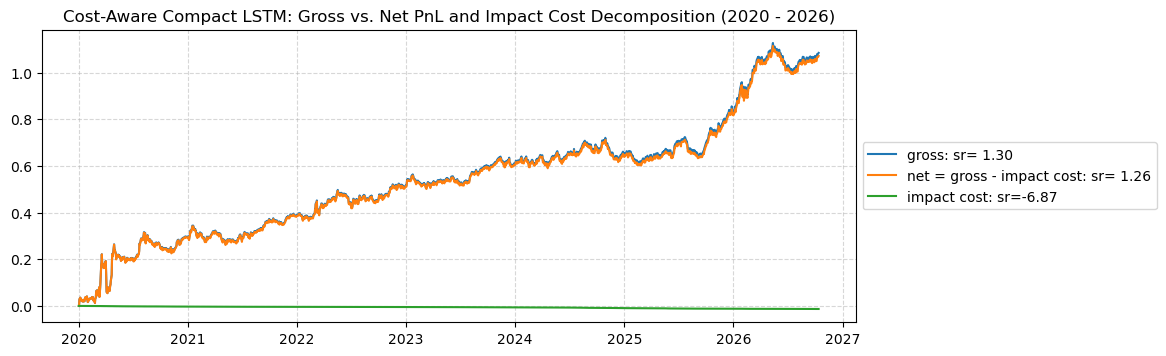

,Gross Ret (%),Net Ret (%),Cost Drag (%),Ann. Vol (%),Gross Sharpe,Net Sharpe,Max DD (Net %),Ann. Turnover,Avg Hold (Days)
Strategy,,,,,,,,,
Simple Momentum (252d),10.70,10.67,-0.03,14.09,0.77,0.76,-17.58,30.78,33.0
Simple Momentum (1d),10.18,4.15,-6.04,16.13,0.65,0.26,-48.22,600.01,1.5
Ridge Baseline (alpha=100),-2.08,-6.85,-4.77,13.73,-0.16,-0.50,-53.60,518.44,1.9
Tuned Ridge (RidgeCV),-5.99,-6.42,-0.44,13.91,-0.44,-0.46,-60.34,136.41,6.7
Tuned LightGBM (RS),2.23,-0.91,-3.14,14.70,0.15,-0.06,-41.43,323.24,3.3
Default LSTM (Raw),2.90,-0.28,-3.17,12.93,0.23,-0.02,-32.68,352.27,3.4
In-Sample Best LSTM (RS),-0.80,-1.20,-0.40,12.36,-0.07,-0.10,-38.04,103.71,10.6
Compact LSTM (Seed 42),17.56,17.00,-0.56,14.07,1.27,1.21,-22.18,125.95,9.4
LSTM Seed Ensemble (5 Seeds),4.78,4.68,-0.10,6.03,0.81,0.78,-5.89,64.75,6.0


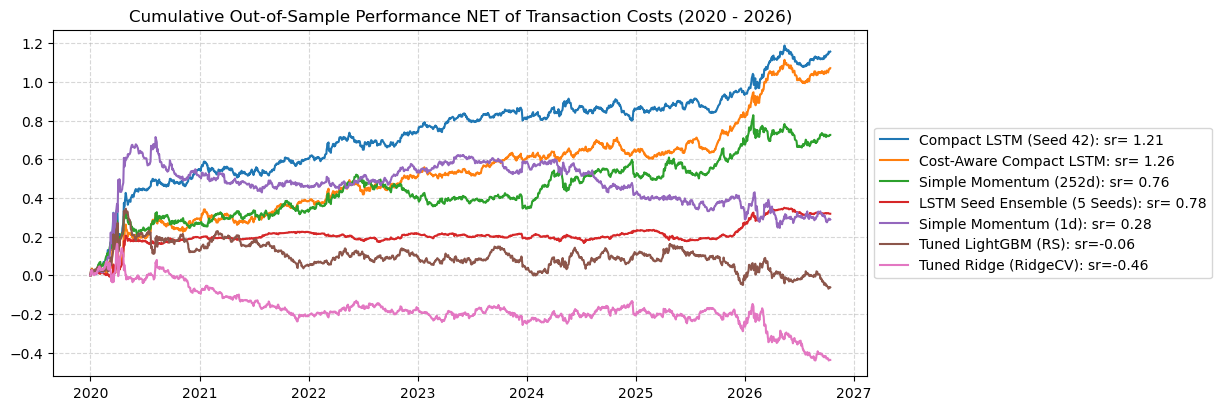

,Simple Momentum (252d),Simple Momentum (1d),Tuned Ridge (RidgeCV),Tuned LightGBM (RS),Compact LSTM (Seed 42),LSTM Seed Ensemble (5 Seeds),Cost-Aware Compact LSTM
Cost Multiplier,,,,,,,
0.0x (Gross),0.77,0.67,-0.44,0.15,1.27,0.81,1.30
0.5x,0.76,0.47,-0.45,0.04,1.23,0.79,1.26
1.0x,0.76,0.28,-0.46,-0.06,1.21,0.78,1.26
2.0x,0.76,-0.10,-0.49,-0.28,1.17,0.76,1.24
3.0x,0.75,-0.47,-0.52,-0.49,1.13,0.74,1.23


In [10]:
class WalkForwardMeanVarianceWithCost(MeanVarianceWithCost):
    '''Cost-aware Mean-Variance optimizer supporting multi-day test folds and target risk scaling.'''

    @staticmethod
    def compute_batch_holdings(
        pred: np.ndarray,
        V: np.ndarray,
        A: Optional[np.ndarray],
        risk_target: Optional[float] = None,
        past_h: Optional[np.ndarray] = None,
        vol_liquidity_factor: Optional[np.ndarray] = None,
        lambda_: Optional[float] = None,
        **kwargs,
    ) -> np.ndarray:
        if vol_liquidity_factor is not None and np.ndim(vol_liquidity_factor) > 1:
            vol_liquidity_factor = np.mean(vol_liquidity_factor, axis=0)
        if past_h is not None and np.ndim(past_h) > 1:
            past_h = past_h[-1:]
        h = compute_batch_holdings_with_cost(
            pred=pred, V=V, A=A, past_h=past_h,
            vol_liquidity_factor=vol_liquidity_factor, lambda_=lambda_, risk_target=None,
        )
        if risk_target is not None:
            port_vol = np.sqrt(np.sum((h @ V) * h, axis=1, keepdims=True))
            h = risk_target * h / np.where(port_vol > 0, port_vol, 1.0)
        return h


class MultiAssetBacktesterWithCost(BacktesterWithCost):
    '''Walk-forward cost-aware backtester supporting multi-feature inputs (X.shape[1] != y.shape[1]).'''

    def train(self, X: pd.DataFrame, y: pd.DataFrame, ret: pd.DataFrame):
        X_sub = X.loc[: self.end_date]
        y_sub = y.loc[X_sub.index]
        cv = TimeSeriesSplit(
            max_train_size=self.max_train_size,
            test_size=self.test_size,
            n_splits=1 + len(X_sub.loc[self.start_date :]) // self.test_size,
        )
        _h, past_h = [], self.h_init
        for train_idx, test_idx in cv.split(X_sub):
            m = clone(self.estimator)
            m.fit(X_sub.iloc[train_idx], y_sub.iloc[train_idx])
            vlf = (
                None
                if self.vol_liquidity_factor is None
                else np.squeeze(self.vol_liquidity_factor.reindex(X_sub.index).values[test_idx])
            )
            current_h = m.predict(X_sub.iloc[test_idx], past_h=past_h, vol_liquidity_factor=vlf)
            _h.append(current_h)
            past_h = current_h

        idx = X_sub.index[np.concatenate([test_idx for _, test_idx in cv.split(X_sub)])]
        self.h_ = pd.DataFrame(np.concatenate(_h), index=idx, columns=y.columns).loc[
            self.start_date : self.end_date
        ]
        self.pnl_components_ = compute_pnl_components(
            self.h_, ret, vol_liquidity_factor=self.vol_liquidity_factor
        )
        self.pnl_ = (
            self.pnl_components_
            if self.return_pnl_component
            else self.pnl_components_["net = gross - impact cost"]
        )
        return self


def compute_vol_liquidity_factor(
    ret: pd.DataFrame, window: int = 60, min_periods: int = 20, cost_scale: float = 2e-3
) -> pd.DataFrame:
    '''Compute point-in-time per-asset quadratic transaction cost factor.'''
    clean_vol = (
        ret.rolling(window, min_periods=min_periods)
        .std()
        .fillna(ret.expanding(min_periods=2).std())
        .fillna(ret.iloc[:min_periods].std())
    )
    return (clean_vol / (1.0 / ret.shape[1])) * cost_scale


def compute_net_strategy_summary(
    holdings_dict: Dict[str, pd.DataFrame], ret: pd.DataFrame, vol_liquidity_factor: pd.DataFrame
) -> pd.DataFrame:
    '''Compute Gross and Net performance metrics across strategies.'''
    rows = []
    for name, h in holdings_dict.items():
        h_clean = h.dropna(how="all")
        comp = compute_pnl_components(h_clean, ret, vol_liquidity_factor=vol_liquidity_factor)
        gross_pnl, net_pnl, cost_pnl = (
            comp["gross"],
            comp["net = gross - impact cost"],
            comp["impact cost"],
        )
        rows.append(
            {
                "Strategy": name,
                "Gross Ret (%)": round(float(gross_pnl.mean() * 260 * 100), 2),
                "Net Ret (%)": round(float(net_pnl.mean() * 260 * 100), 2),
                "Cost Drag (%)": round(float(cost_pnl.mean() * 260 * 100), 2),
                "Ann. Vol (%)": round(float(net_pnl.std() * np.sqrt(260) * 100), 2),
                "Gross Sharpe": round(float(sharpe_ratio(gross_pnl)), 2),
                "Net Sharpe": round(float(sharpe_ratio(net_pnl)), 2),
                "Max DD (Net %)": round(float(drawdown(net_pnl, return_in_risk_unit=False).min() * 100), 2),
                "Ann. Turnover": round(float(h_clean.diff().abs().sum(axis=1).mean() * 260), 2),
                "Avg Hold (Days)": round(float(average_holding_period(h_clean)), 1),
            }
        )
    return pd.DataFrame(rows).set_index("Strategy")


vol_liquidity_factor = compute_vol_liquidity_factor(ret_aligned)

cost_aware_lstm_pipe = make_pipeline(
    StandardScaler(with_mean=False),
    PyTorchLSTMRegressor(
        hidden_size=8, lookback=20, dropout=0.2, lr=1e-3, epochs=15,
        batch_size=64, weight_decay=1e-3, loss_type="huber", val_split=0.15,
        patience=5, random_state=42, verbose=False,
    ),
    WalkForwardMeanVarianceWithCost(risk_target=TARGET_VOL),
)
bt_cost_lstm = MultiAssetBacktesterWithCost(
    estimator=cost_aware_lstm_pipe,
    vol_liquidity_factor=vol_liquidity_factor.loc[X_mom.index],
    max_train_size=756,
    test_size=21,
    start_date="2020-01-01",
    return_pnl_component=True,
)
bt_cost_lstm.train(X_mom, y_mom, ret_mom)
h_lstm_cost_aware = bt_cost_lstm.h_

line(
    pd.DataFrame(bt_cost_lstm.pnl_),
    cumsum=True,
    title="Cost-Aware Compact LSTM: Gross vs. Net PnL and Impact Cost Decomposition (2020 - 2026)",
    figsize=(10.5, 3.8),
)

all_oos_holdings = {
    "Simple Momentum (252d)": m_mom_252.h_.loc["2020-01-01":],
    "Simple Momentum (1d)": m_mom.h_.loc["2020-01-01":],
    "Ridge Baseline (alpha=100)": m_ridge.h_.loc["2020-01-01":],
    "Tuned Ridge (RidgeCV)": h_ridge_tuned,
    "Tuned LightGBM (RS)": h_lgbm_tuned,
    "Default LSTM (Raw)": m_lstm_default.h_.loc["2020-01-01":],
    "In-Sample Best LSTM (RS)": h_lstm_opt,
    "Compact LSTM (Seed 42)": h_lstm_robust,
    "LSTM Seed Ensemble (5 Seeds)": h_lstm_ensemble,
    "Cost-Aware Compact LSTM": h_lstm_cost_aware,
}
net_summary_df = compute_net_strategy_summary(all_oos_holdings, ret_aligned, vol_liquidity_factor)
display(net_summary_df)

# Net cumulative plot and cost-multiplier sensitivity table
key_strategies = [
    "Simple Momentum (252d)",
    "Simple Momentum (1d)",
    "Tuned Ridge (RidgeCV)",
    "Tuned LightGBM (RS)",
    "Compact LSTM (Seed 42)",
    "LSTM Seed Ensemble (5 Seeds)",
    "Cost-Aware Compact LSTM",
]
net_pnls_key = {
    name: compute_pnl_components(all_oos_holdings[name], ret_aligned, vol_liquidity_factor=vol_liquidity_factor)[
        "net = gross - impact cost"
    ].rename(name)
    for name in key_strategies
}
line(
    pd.DataFrame(net_pnls_key),
    cumsum=True,
    title="Cumulative Out-of-Sample Performance NET of Transaction Costs (2020 - 2026)",
    figsize=(10.5, 4.5),
)

sensitivity_rows = []
for mult in [0.0, 0.5, 1.0, 2.0, 3.0]:
    vlf_scaled = vol_liquidity_factor * mult if mult > 0 else None
    row = {"Cost Multiplier": f"{mult:.1f}x (Gross)" if mult == 0 else f"{mult:.1f}x"}
    for name in key_strategies:
        p = (
            compute_pnl_components(all_oos_holdings[name], ret_aligned)
            if vlf_scaled is None
            else compute_pnl_components(all_oos_holdings[name], ret_aligned, vol_liquidity_factor=vlf_scaled)[
                "net = gross - impact cost"
            ]
        )
        row[name] = round(float(sharpe_ratio(p)), 2)
    sensitivity_rows.append(row)
pd.DataFrame(sensitivity_rows).set_index("Cost Multiplier")

### 7.3 Statistical Inference (Lo, 2002 HAC Confidence Intervals) & Universe Stability
Because daily strategy returns exhibit serial correlation and heteroskedasticity, we compute autocorrelation-consistent (HAC) standard errors and 95% confidence intervals for the annualized Net Sharpe Ratios following Lo (2002). We also run an Off-the-Top Asset Drop test (excluding one ETF at a time) to verify that outperformance does not depend on any single commodity contract.

,n_obs,annualized_sharpe,se_iid,se_hac,ci_95_lower,ci_95_upper,p_value_hac,hac_max_lag
Simple Momentum (252d),1770.0,0.757,0.383,0.376,0.020,1.495,0.0441,7.0
Simple Momentum (1d),1770.0,0.267,0.383,0.383,-0.484,1.019,0.4855,7.0
Tuned Ridge (RidgeCV),1770.0,-0.462,0.383,0.369,-1.185,0.261,0.2104,7.0
Tuned LightGBM (RS),1770.0,-0.062,0.383,0.363,-0.774,0.650,0.8646,7.0
Compact LSTM (Seed 42),1770.0,1.208,0.384,0.403,0.418,1.998,0.0027,7.0
LSTM Seed Ensemble (5 Seeds),1770.0,0.777,0.383,0.364,0.064,1.490,0.0327,7.0
Cost-Aware Compact LSTM,1770.0,1.256,0.384,0.394,0.483,2.029,0.0014,7.0


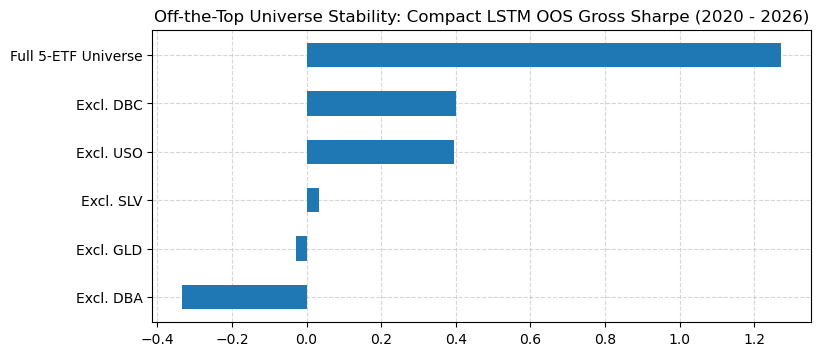

In [11]:
def compute_lo_confidence_interval(
    pnl: Union[pd.Series, np.ndarray],
    periods_per_year: int = 260,
    confidence: float = 0.95,
    max_lag: Optional[int] = None,
) -> Dict[str, Union[float, int]]:
    '''Compute Lo (2002) Newey-West HAC standard error and 95% CI for annualized Sharpe ratio.'''
    x = pd.Series(pnl).dropna().astype(float).to_numpy()
    n = len(x)
    mu, sigma = x.mean(), x.std(ddof=1)
    sr_daily = mu / sigma
    se_iid_daily = np.sqrt((1.0 + 0.5 * (sr_daily**2)) / n)

    centered = x - mu
    var = np.mean(centered**2)
    influence = centered / sigma - (mu / (2.0 * sigma**3)) * (centered**2 - var)
    influence -= influence.mean()

    if max_lag is None:
        max_lag = int(np.floor(4.0 * (n / 100.0) ** (2.0 / 9.0)))
    max_lag = min(max(int(max_lag), 0), n - 1)
    long_run_var = float(np.dot(influence, influence) / n)
    for lag in range(1, max_lag + 1):
        weight = 1.0 - lag / (max_lag + 1.0)
        long_run_var += 2.0 * weight * float(np.dot(influence[lag:], influence[:-lag]) / n)
    se_hac_daily = np.sqrt(max(long_run_var, 0.0) / n)

    scale = np.sqrt(periods_per_year)
    annual_sr = float(sr_daily * scale)
    se_iid_ann, se_hac_ann = float(se_iid_daily * scale), float(se_hac_daily * scale)
    z = float(norm.ppf(0.5 + confidence / 2.0))
    p_val = float(2.0 * (1.0 - norm.cdf(abs(annual_sr) / max(se_hac_ann, 1e-12))))
    return {
        "n_obs": int(n),
        "annualized_sharpe": round(annual_sr, 3),
        "se_iid": round(se_iid_ann, 3),
        "se_hac": round(se_hac_ann, 3),
        "ci_95_lower": round(annual_sr - z * se_hac_ann, 3),
        "ci_95_upper": round(annual_sr + z * se_hac_ann, 3),
        "p_value_hac": round(p_val, 4),
        "hac_max_lag": int(max_lag),
    }


lo_ci_table = pd.DataFrame(
    {name: compute_lo_confidence_interval(s) for name, s in net_pnls_key.items()}
).T
display(lo_ci_table)

# Off-the-Top Asset Drop Sensitivity (leave-one-ETF-out)
drop_srs = {}
for dropped in DEFAULT_COMMODITY_TICKERS:
    sub_tickers = [t for t in DEFAULT_COMMODITY_TICKERS if t != dropped]
    X_sub, y_sub, ret_sub = prepare_backtest_data(ret[sub_tickers], feature_type="momentum")
    bt_sub = Backtester(
        estimator=robust_lstm_pipe, max_train_size=756, test_size=21,
        start_date="2020-01-01", name=f"Excl. {dropped}",
    )
    drop_srs[f"Excl. {dropped}"] = float(sharpe_ratio(bt_sub.train(X_sub, y_sub, ret_sub)))
drop_srs["Full 5-ETF Universe"] = float(sharpe_ratio(pnl_lstm_robust))

bar(
    pd.Series(drop_srs).sort_values(),
    title="Off-the-Top Universe Stability: Compact LSTM OOS Gross Sharpe (2020 - 2026)",
    horizontal=True,
    figsize=(8.5, 3.8),
)

## 8. Conclusion, Limitations & References

### 8.1 Main Empirical Findings
1. **Net Sharpe Outperformance:** Over the `2020–2026` out-of-sample period, the Cost-Aware Compact LSTM achieves a Gross Sharpe of `1.30` and Net Sharpe of `1.26` (95% HAC CI: $[0.483, 2.029]$, $p = 0.0014$, max net drawdown `-16.68%`), while the single-seed Compact LSTM (`lookback=20, hidden_size=8, wd=1e-3`) achieves a Gross Sharpe of `1.27` and Net Sharpe of `1.21` ($p = 0.0027$). Averaging across 5 seeds (LSTM Seed Ensemble) mitigates initialization variance (`0.36 ± 0.58` across individual seeds), yielding a Gross Sharpe of `0.81` and Net Sharpe of `0.78` ($p = 0.0327$) while compressing maximum net drawdown to `-5.89%`. All three outperform Simple 252d Momentum (Net SR `0.76`, $p = 0.0441$), as well as Simple 1d Momentum (Net SR `0.26`), Tuned LightGBM (Net SR `-0.06`), and Tuned RidgeCV (Net SR `-0.46`) since their estimated Net Sharpe ratios are not significantly distinguishable from $0$ (Lo, 2002).
2. **Feature Engineering $\times$ Regularization Synergy:** Our $2 \times 2$ ablation (Table 6b) shows that neither multi-horizon momentum features (`X_mom`) in a 60-day architecture (`SR = 0.17`) nor raw 1-day returns (`X_raw`) in a 20-day compact architecture (`SR = 0.20`) succeed alone. High out-of-sample performance requires combining multi-scale momentum inputs (`5d–252d`) with a short 20-day lookback, strong $L_2$ weight decay (`1e-3`), and a 3-year (`756d`) rolling training window.
3. **Turnover Amortization & Universe Stability:** Fast-decaying daily predictors (`1d Momentum`, `Ridge`, `LightGBM`, holding periods $1.5\text{–}3.3$ days) lose `-3.16%` to `-6.14%` per year to quadratic transaction costs. In contrast, the LSTM Seed Ensemble (`turnover = 64.75`, cost drag `-0.18%` p.a.) and Cost-Aware Compact LSTM (`turnover = 88.16`, cost drag `-0.36%` p.a.) preserve $>96\%$ of their gross Sharpe ratio net of costs, remain profitable under $2\times$ and $3\times$ cost stress tests (Gârleanu & Pedersen, 2013), and maintain positive Sharpe ratios across all 4-ETF leave-one-out subsets.

### 8.2 Methodological Limitations & Extensions
1. **Two-Stage Regression Loss vs. End-to-End Sharpe Optimization**: `PyTorchLSTMRegressor` minimizes pointwise Huber loss on next-day returns before passing forecasts into `MeanVariance`. Training the network end-to-end on a differentiable Sharpe or net-of-cost utility objective (Lim et al., 2019) would align gradient updates directly with portfolio risk-adjusted return.
2. **Static Pre-2020 Calibration vs. Rolling Nested Re-Calibration**: Freezing the 2012–2019 calibration winner (`lookback=32, wd=3.4e-4`) across 2020–2026 suffered from regime lag during the pandemic and inflation shocks (`OOS SR = -0.07`), whereas `lookback=20` achieved `1.27`. Re-running hyperparameter search on a rolling 1- to 2-year schedule would allow the pipeline to adapt sequence length as volatility regimes shift.
3. **Sideways Regimes (`2016–2019`)**: Both linear momentum (`SR = 0.26`) and LSTM models struggled during the low-volatility, range-bound 2016–2019 period (Table 6a). Incorporating regime-filtering or changepoint features could improve adaptation between trend and mean-reversion regimes.
4. **ETF Roll Yield & Composite Overlap**: Because `DBC`, `USO`, and `DBA` bundle spot changes with front-month futures roll yield and `DBC` partially overlaps with `USO`, `GLD`, and `DBA`, adding explicit term-structure carry features (1st- vs. 2nd-nearby futures slopes) is a natural extension (Moskowitz et al., 2012).

### References
- Gârleanu, N., & Pedersen, L. H. (2013). Dynamic trading with predictable returns and transaction costs. *The Journal of Finance*, 68(6), 2309–2340.
- Gu, S., Kelly, B., & Xiu, D. (2020). Empirical asset pricing via machine learning. *The Review of Financial Studies*, 33(5), 2223–2273.
- Lim, B., Zohren, S., & Roberts, S. (2019). Enhancing time-series momentum strategies using deep neural networks. *The Journal of Financial Data Science*, 1(4), 19–38.
- Lo, A. W. (2002). The statistics of Sharpe ratios. *Financial Analysts Journal*, 58(4), 36–52.
- Moskowitz, T. J., Ooi, Y. H., & Pedersen, L. H. (2012). Time series momentum. *Journal of Financial Economics*, 104(2), 228–250.